In [12]:
from main import *

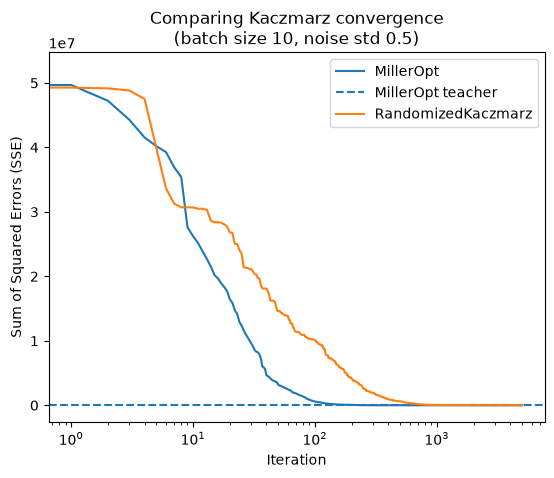

In [13]:
# Generate system
rng = np.random.default_rng(seed=1)
n, d = (100, 50)
n_noised = n // 10
A, x, b = get_system(rng, n, d)

b_noise_scale = 0.5
noised_indices = rng.choice(n, size=n_noised, replace=False)
b_noised = b
b_noised[noised_indices] += rng.normal(scale=b_noise_scale, size=n_noised)

x_teacher = x + 0.6 * rng.normal(size=d)

x0 = rng.normal(scale=1000, size=d)

common_params = dict(
    x0=x0,
    A=A,
    b=b_noised,
    x_sol=x,
    batch_size=10,
    maxiter=5000
)

sols = [
    MillerOpt(**common_params, teacher=x_teacher, noised_indices=noised_indices),
    RandomizedKaczmarz(**common_params),
]

for sol in sols:
    sol.solve()

comparison = Comparison(sols)
comparison.plot_residuals(
    title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
    logx=True,
    logy=False
)

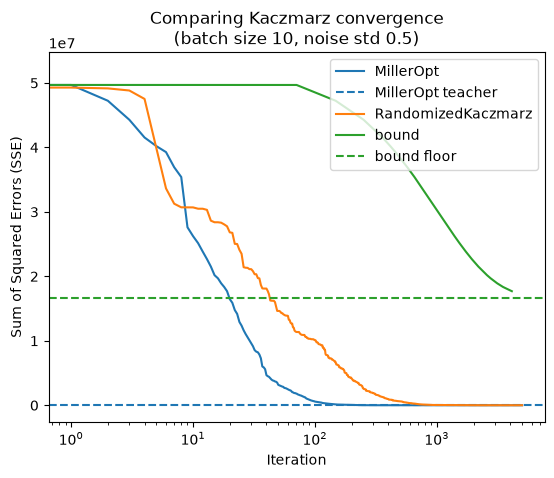

In [14]:
time_bounds = np.array(sols[0].diagnostics["time bounds"])

comparison.plot_residuals(
    title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
    logx=True,
    logy=False
)

plt.plot(time_bounds[:, 0], time_bounds[:, 1], color="tab:green", label="bound")
plt.axhline(sols[0].tb_floor, label=f"bound floor", ls="--", color="tab:green")
plt.legend()
plt.show()

In [15]:
sols[0].tb_floor

np.float64(16707271.989980664)

In [16]:
time_bounds

array([[0.00000000e+00, 5.21270358e+07],
       [7.07084013e+01, 4.96878164e+07],
       [1.47828684e+02, 4.72398921e+07],
       ...,
       [           nan, 1.49418052e+01],
       [           nan, 1.49417792e+01],
       [           nan, 1.49376791e+01]], shape=(5000, 2))